# FP-Growth: Frequent Rideshare Routes

Goal: find the most frequent rideshare routes between community areas, and check how many run along existing 'L' lines (issue #13).

Data: cleaned trips from 2023 onward where both pickup and dropoff community areas are known, processed by `src/mining/fpgrowth_routes.py` on Dataproc. Exact origin-destination (OD) counts use all of these trips. FP-Growth uses a 10% random sample. Each trip becomes a basket of five items: `from=` area, `to=` area, `time=` band, `day=` weekday or weekend, and `dist=` band. Minimum support is 0.2% and minimum confidence is 10%.

In [7]:
from pathlib import Path
import glob
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

# Folder with the Dataproc outputs (downloaded with gcloud storage cp -r).
# Use "mining_test" for the 200k-sample test run, "mining" for the full-data run.
RESULTS = ROOT / "results" / "mining"
FIGS = ROOT / "docs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

def read_spark_csv(name):
    """Spark writes each output as a folder with one part-*.csv file inside."""
    files = glob.glob(str(RESULTS / name / "part-*.csv"))
    assert files, f"no CSV found in {RESULTS / name}"
    return pd.read_csv(files[0])

od = read_spark_csv("od_pairs")
rules = read_spark_csv("fp_rules")
itemsets = read_spark_csv("fp_itemsets")
access = pd.read_csv(ROOT / "results" / "cta_access_by_area.csv")
names = access.set_index("area")["name"].replace({"Ohare": "O'Hare"})
print(len(od), "OD pairs (top 500 saved),", len(itemsets), "frequent itemsets,", len(rules), "rules")

500 OD pairs (top 500 saved), 2098 frequent itemsets, 4234 rules


## Most frequent routes

In [8]:
od["from_name"] = od["from_area"].map(names)
od["to_name"] = od["to_area"].map(names)
od["share_pct"] = (od["support"] * 100).round(2)
od["same_area"] = od["from_area"] == od["to_area"]
print(f"Top 20 routes = {od.head(20)['support'].sum():.1%} of all trips")
print(f"Trips that start and end in the same area (in the top 500): {od[od.same_area]['support'].sum():.1%}")
od.head(20)[["from_name", "to_name", "count", "share_pct", "same_area"]]

Top 20 routes = 28.5% of all trips
Trips that start and end in the same area (in the top 500): 14.9%


,from_name,to_name,count,share_pct,same_area
0,Near North Side,Near North Side,10203256,3.83,True
1,Near North Side,Loop,6082943,2.28,False
2,Near North Side,Near West Side,5578435,2.09,False
3,Loop,Near North Side,5524704,2.07,False
4,Near West Side,Near North Side,5144369,1.93,False
5,Near West Side,Near West Side,3898305,1.46,True
6,Loop,Near West Side,3348348,1.26,False
7,Near West Side,Loop,3216479,1.21,False
8,Near North Side,Lincoln Park,3194829,1.20,False
9,Lake View,Lake View,3189055,1.20,True


The most common single route is a trip that starts and ends inside the Near North Side (10.2 million trips, 3.8% of all trips). The top 20 routes alone cover 28.5% of all trips, so rideshare use is very concentrated around downtown. Most of them connect the Near North Side, the Loop, the Near West Side, Lincoln Park and Lake View. Five of the top 20 routes stay inside one area (Near North Side, Near West Side, Lake View, the Loop and Hyde Park), and same-area trips make up 14.9% of the trips in the top 500 routes. These are short trips that people could often walk or take a bus for.

## Routes between areas, and the 'L'

In [9]:
# 'L' lines with a station inside each area (from the CTA stop list + area boundaries, as in notebook 04)
# A route counts as 'L'-connected when one 'L' line has a station in both areas (no transfer needed).
SUP = ROOT / "data" / "raw" / "supporting"
LINES = {"RED": "Red", "BLUE": "Blue", "G": "Green", "BRN": "Brown", "P": "Purple",
         "Y": "Yellow", "PNK": "Pink", "O": "Orange"}
stops = pd.read_csv(SUP / "cta_L_stops.csv")
stops.columns = stops.columns.str.strip().str.upper()
nums = stops["LOCATION"].astype(str).str.findall(r"-?\d+\.\d+")
stops["lat"] = nums.apply(lambda v: next(float(x) for x in v if 41 < float(x) < 43))
stops["lon"] = nums.apply(lambda v: next(float(x) for x in v if -89 < float(x) < -87))
areas = gpd.read_file(SUP / "community_areas.geojson")
num_col = [c for c in areas.columns if c.lower().startswith("area_num")][0]
areas["area"] = areas[num_col].astype(float).astype(int)
pts = gpd.GeoDataFrame(stops, geometry=gpd.points_from_xy(stops["lon"], stops["lat"]), crs="EPSG:4326")
inside = gpd.sjoin(pts, areas[["area", "geometry"]].to_crs("EPSG:4326"), predicate="within")
lines = {a: {LINES[c] for c in LINES if g[c].astype(str).str.strip().str.lower().eq("true").any()}
         for a, g in inside.groupby("area")}
print({names.get(a, a): sorted(l) for a, l in lines.items() if a in (8, 32, 28, 76)})
dist = access.set_index("area")["dist_to_L_km"]

between = od[~od.same_area].copy()
between["shared_lines"] = [", ".join(sorted(lines.get(a, set()) & lines.get(b, set())))
                           for a, b in zip(between["from_area"], between["to_area"])]
between["L_connected"] = between["shared_lines"] != ""
between["max_dist_to_L_km"] = [max(dist.get(a, 99), dist.get(b, 99))
                               for a, b in zip(between["from_area"], between["to_area"])]

top = between.head(50)
print(f"Of the top 50 routes between different areas, {top.L_connected.sum()} run along one 'L' line "
      f"({top[top.L_connected]['support'].sum() / top['support'].sum():.0%} of their trips).")
top.head(20)[["from_name", "to_name", "count", "share_pct", "L_connected", "shared_lines", "max_dist_to_L_km"]]

{'Near North Side': ['Brown', 'Purple', 'Red'], 'Near West Side': ['Blue', 'Green', 'Pink'], 'Loop': ['Blue', 'Brown', 'Green', 'Orange', 'Pink', 'Purple', 'Red'], "O'Hare": ['Blue']}
Of the top 50 routes between different areas, 30 run along one 'L' line (64% of their trips).


,from_name,to_name,count,share_pct,L_connected,shared_lines,max_dist_to_L_km
1,Near North Side,Loop,6082943,2.28,True,"Brown, Purple, Red",0.38
2,Near North Side,Near West Side,5578435,2.09,False,,0.40
3,Loop,Near North Side,5524704,2.07,True,"Brown, Purple, Red",0.38
4,Near West Side,Near North Side,5144369,1.93,False,,0.40
6,Loop,Near West Side,3348348,1.26,True,"Blue, Green, Pink",0.40
7,Near West Side,Loop,3216479,1.21,True,"Blue, Green, Pink",0.40
8,Near North Side,Lincoln Park,3194829,1.20,True,"Brown, Purple, Red",0.38
10,Lincoln Park,Near North Side,3163433,1.19,True,"Brown, Purple, Red",0.38
12,Near North Side,Lake View,2988771,1.12,True,"Brown, Purple, Red",0.41
13,Lake View,Near North Side,2949720,1.11,True,"Brown, Purple, Red",0.41


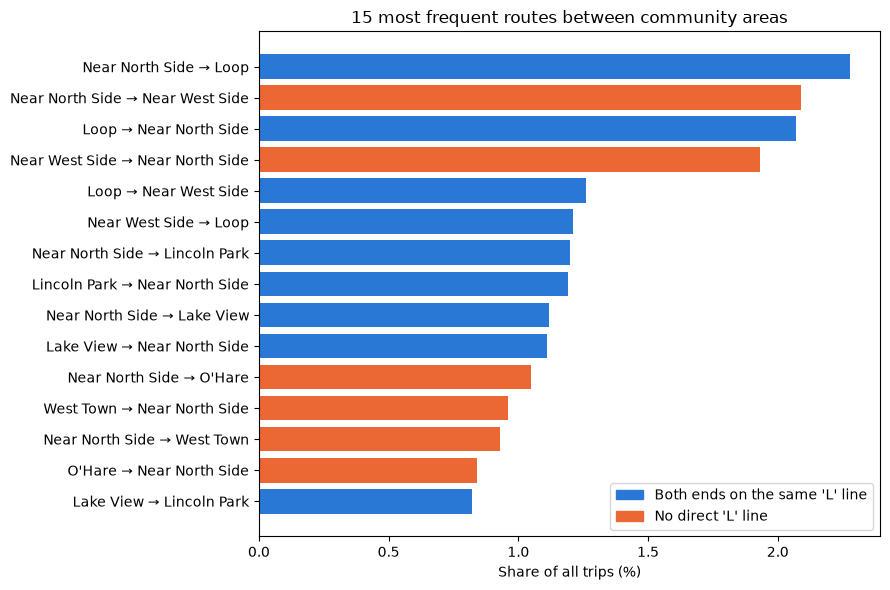

In [10]:
t15 = between.head(15).iloc[::-1]
labels = t15["from_name"] + " → " + t15["to_name"]
colors = ["#2a78d6" if c else "#eb6834" for c in t15["L_connected"]]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(labels, t15["share_pct"], color=colors)
ax.set_xlabel("Share of all trips (%)")
ax.set_title("15 most frequent routes between community areas")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#2a78d6", label="Both ends on the same 'L' line"),
                   Patch(color="#eb6834", label="No direct 'L' line")], loc="lower right")
plt.tight_layout()
plt.savefig(FIGS / "top_routes.png", dpi=150, bbox_inches="tight")
plt.show()

Of the 50 busiest routes between different areas, 30 can be done on one 'L' line without a transfer, and they carry 64% of the trips on these routes. So most of the busiest rideshare trips copy a train route that already exists. The clearest example is Loop ↔ O'Hare: about 3.4 million trips even though the Blue Line goes directly there. The busiest routes with no single 'L' line are Near North Side ↔ Near West Side (10.7 million trips, about 4% of all trips), West Town ↔ Near North Side (5.0 million) and Near North Side ↔ O'Hare (5.1 million). All of these need a transfer between lines. These are our first transit-gap candidates, because a transfer adds time and makes rideshare more attractive.

## Association rules: when and how far

In [11]:
# Rules that predict a destination from an origin (plus time, day or distance)
r = rules.copy()
route_rules = r[r["then_item"].str.startswith("to=") & r["if_items"].str.contains("from=")].copy()
route_rules["from_area"] = route_rules["if_items"].str.extract(r"from=(\d+)")[0].astype(int)
route_rules["to_area"] = route_rules["then_item"].str.extract(r"to=(\d+)")[0].astype(int)
route_rules = route_rules[route_rules["from_area"] != route_rules["to_area"]]
route_rules["route"] = route_rules["from_area"].map(names) + " → " + route_rules["to_area"].map(names)
print(len(route_rules), "rules predict a different destination area")
route_rules.sort_values("lift", ascending=False).head(15)[
    ["if_items", "then_item", "route", "support", "confidence", "lift"]].round(3)

288 rules predict a different destination area


,if_items,then_item,route,support,confidence,lift
42,day=weekday + dist=10+mi + from=8 + time=morning,to=76,Near North Side → O'Hare,0.002,0.698,15.759
43,dist=10+mi + from=8 + time=morning,to=76,Near North Side → O'Hare,0.003,0.695,15.669
48,day=weekday + dist=10+mi + from=32 + time=midday,to=76,Loop → O'Hare,0.003,0.669,15.103
49,day=weekday + dist=10+mi + from=8 + time=midday,to=76,Near North Side → O'Hare,0.003,0.669,15.085
51,dist=10+mi + from=8 + time=midday,to=76,Near North Side → O'Hare,0.004,0.661,14.903
52,dist=10+mi + from=32 + time=midday,to=76,Loop → O'Hare,0.003,0.659,14.870
59,dist=10+mi + from=7,to=76,Lincoln Park → O'Hare,0.002,0.617,13.922
60,day=weekday + dist=10+mi + from=6,to=76,Lake View → O'Hare,0.002,0.603,13.595
61,day=weekday + dist=10+mi + from=8,to=76,Near North Side → O'Hare,0.008,0.602,13.578
62,day=weekday + dist=10+mi + from=32,to=76,Loop → O'Hare,0.005,0.587,13.248


In [12]:
# Rules about time of day and day of week (for example: airport trips and late-night trips)
context = r[r["then_item"].str.startswith(("time=", "day="))]
context.sort_values("lift", ascending=False).head(15)[["if_items", "then_item", "support", "confidence", "lift"]].round(3)

,if_items,then_item,support,confidence,lift
516,day=weekend + dist=0-2mi + from=6,time=night,0.002,0.285,2.526
568,day=weekend + dist=0-2mi + to=6,time=night,0.002,0.265,2.345
578,day=weekend + from=6,time=night,0.007,0.262,2.318
594,day=weekend + from=22,time=night,0.003,0.256,2.271
603,day=weekday + dist=5-10mi + to=32,time=morning,0.004,0.329,2.238
605,day=weekend + dist=5-10mi + from=8,time=night,0.002,0.252,2.236
616,day=weekend + dist=2-5mi + from=6,time=night,0.003,0.249,2.204
623,dist=2-5mi + time=night + to=6,day=weekend,0.003,0.713,2.183
624,dist=2-5mi + from=7 + time=night,day=weekend,0.002,0.713,2.183
631,time=night + to=7,day=weekend,0.004,0.708,2.168


Example: if a trip starts in the Near North Side on a weekday morning and is longer than 10 miles, it goes to O'Hare 69.8% of the time (confidence). Only about 4% of all trips go to O'Hare, so this is 15.8 times more likely than for an average trip (lift). The rule covers 0.2% of all trips (support). Support tells us how common a pattern is, confidence tells us how often the "then" part happens when the "if" part is true, and lift tells us how much stronger that is than chance (lift above 1 means the items really go together). The second table shows night trips: short weekend trips from Lake View are 2.5 times more likely than average to happen at night (12–6 AM), and 71% of night trips to Lincoln Park happen on weekends, which matches the nightlife pattern of Cluster 0 in the K-means notebook. Rules where a trip starts and ends in the same area (for example short trips inside Austin, lift 56) get very high lift partly because each single area is a rare item, so we look at confidence and support together with lift.

## What this means for the project

- Most busy rideshare routes already have a direct 'L' line, so in those cases people choose rideshare for speed or convenience, not because transit is missing.
- The busy routes that need a transfer (Near North Side ↔ Near West Side, Near North Side ↔ West Town, Near North Side ↔ O'Hare) are the first transit-gap candidates. In Sprint 3 we will add the number of transfers and travel time for these routes to the transit-gap score.
- FP-Growth was run on a 10% random sample (26.6 million trips) with minimum support 0.2%, so only patterns covering at least about 53,000 sampled trips appear. Rarer routes in Cluster 1 areas need a lower support or a separate analysis, which we will do in Sprint 3.